# 3 · Evaluación en prueba por segmento y uso de la API

Entrenado con todo lo anterior a 2018-01-01, evaluado con lo que cada usuario calificó con ≥ 4 estrellas entre
2018-01 y 2019-11 (sin repetir lo ya visto). Top-10. Métricas:

- **Precision@10, Recall@10, NDCG@10, MAP@10**: exactitud del ranking (NDCG premia acertar arriba).
- **Cobertura**: % del catálogo que aparece en alguna lista.
- **Novedad**: −log2 de la fracción de usuarios a los que les gustó (más bits = menos obvio).
- **Diversidad**: 1 − similitud de géneros promedio entre pares de la lista.
- **Sesgo de popularidad**: percentil medio de popularidad de lo recomendado, % de cola larga y Δ frente a lo que el
  propio usuario consume.

In [1]:
import json, sys
import numpy as np, pandas as pd
from IPython.display import Image, display
from recomendador import config as C
sys.path.insert(0, str(C.RAIZ))  # para importar api.main
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
m = pd.read_csv(C.REPORTES / "metricas_prueba.csv")
cols = ["modelo", "usuarios", "precision@10", "recall@10", "ndcg@10", "ndcg_ic95_bajo", "ndcg_ic95_alto", "map@10"]
m[m.segmento == "existentes (todos)"][cols].sort_values("ndcg@10", ascending=False)

,modelo,usuarios,precision@10,recall@10,ndcg@10,ndcg_ic95_bajo,ndcg_ic95_alto,map@10
30,EASE (referencia),6267,0.1413,0.0698,0.1665,0.1613,0.1720,0.0947
24,Híbrido (ALS + contenido + recientes),6267,0.1424,0.0722,0.1660,0.1609,0.1710,0.0920
14,ALS implícito,6267,0.1268,0.0595,0.1481,0.1431,0.1533,0.0815
9,Popularidad reciente,6267,0.1055,0.0568,0.1246,0.1202,0.1293,0.0664
19,Contenido (géneros + genome),6267,0.0940,0.0454,0.1086,0.1040,0.1129,0.0572
4,Popularidad global,6267,0.0669,0.0313,0.0800,0.0763,0.0837,0.0416


## Por segmento

In [3]:
orden = ["nuevos (onboarding)", "pocos (1-20)", "medios (21-100)", "muchos (>100)", "existentes (todos)"]
m.pivot(index="modelo", columns="segmento", values="ndcg@10")[orden].sort_values("existentes (todos)", ascending=False)

segmento,nuevos (onboarding),pocos (1-20),medios (21-100),muchos (>100),existentes (todos)
modelo,,,,,
EASE (referencia),0.3846,0.1913,0.1646,0.1644,0.1665
Híbrido (ALS + contenido + recientes),0.4151,0.2114,0.1601,0.1634,0.1660
ALS implícito,0.3666,0.1676,0.1500,0.1446,0.1481
Popularidad reciente,0.3640,0.1864,0.1099,0.1244,0.1246
Contenido (géneros + genome),0.3502,0.1721,0.1087,0.1005,0.1086
Popularidad global,0.2858,0.1454,0.0812,0.0712,0.0800
Contenido solo con géneros elegidos,0.2254,NaN,NaN,NaN,NaN


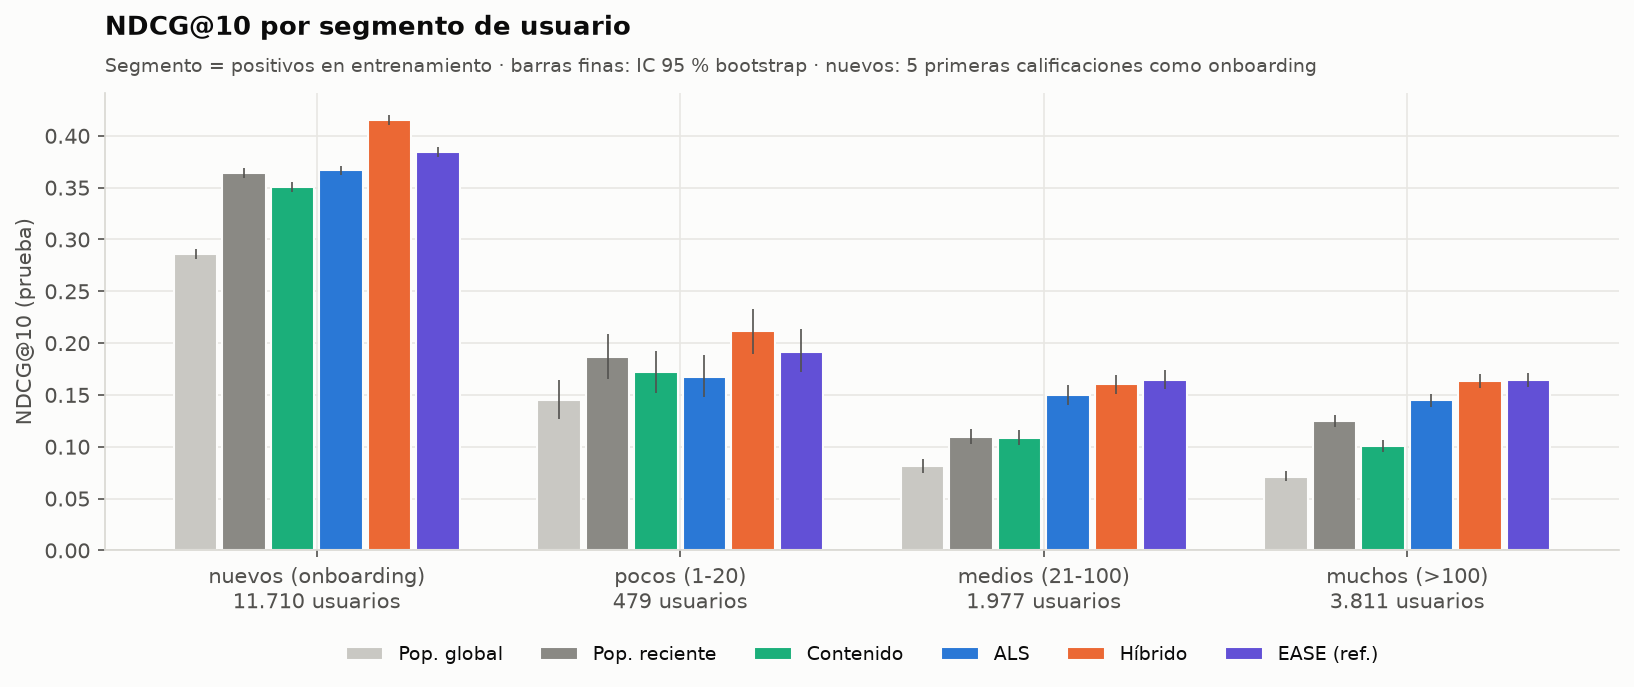

In [4]:
display(Image(str(C.FIGURAS / "02_ndcg_por_segmento.png")))

### ¿La diferencia del híbrido frente al ALS es real? Bootstrap pareado por usuario

In [5]:
pu = pd.read_parquet(C.REPORTES / "metricas_por_usuario.parquet")
rng = np.random.default_rng(42)
filas = []
for seg in orden[:-1]:
    a = pu[(pu.modelo == "Híbrido (ALS + contenido + recientes)") & (pu.segmento == seg)].set_index("usuario")["ndcg"]
    for rival in ["ALS implícito", "Popularidad reciente", "Contenido (géneros + genome)"]:
        b = pu[(pu.modelo == rival) & (pu.segmento == seg)].set_index("usuario")["ndcg"].reindex(a.index)
        d = (a - b).to_numpy()
        medias = d[rng.integers(0, len(d), (2000, len(d)))].mean(axis=1)
        filas.append({"segmento": seg, "híbrido menos": rival, "Δ NDCG": d.mean(),
                      "IC95 bajo": np.quantile(medias, .025), "IC95 alto": np.quantile(medias, .975),
                      "usuarios": len(d)})
ic = pd.DataFrame(filas)
ic.round(5).to_csv(C.REPORTES / "bootstrap_pareado.csv", index=False)
ic

,segmento,híbrido menos,Δ NDCG,IC95 bajo,IC95 alto,usuarios
0,nuevos (onboarding),ALS implícito,0.0485,0.0455,0.0514,11710
1,nuevos (onboarding),Popularidad reciente,0.0511,0.0478,0.0542,11710
2,nuevos (onboarding),Contenido (géneros + genome),0.0649,0.0621,0.0680,11710
3,pocos (1-20),ALS implícito,0.0438,0.0306,0.0578,479
4,pocos (1-20),Popularidad reciente,0.0250,0.0086,0.0417,479
5,pocos (1-20),Contenido (géneros + genome),0.0392,0.0248,0.0535,479
6,medios (21-100),ALS implícito,0.0102,0.0064,0.0137,1977
7,medios (21-100),Popularidad reciente,0.0503,0.0423,0.0583,1977
8,medios (21-100),Contenido (géneros + genome),0.0514,0.0438,0.0588,1977
9,muchos (>100),ALS implícito,0.0187,0.0158,0.0218,3811


## Más allá de la exactitud

In [6]:
cols = ["modelo", "ndcg@10", "cobertura_pct", "novedad_bits", "diversidad_generos", "percentil_pop_medio",
        "cola_larga_pct", "delta_pop_vs_historial"]
m[m.segmento == "existentes (todos)"][cols].sort_values("ndcg@10", ascending=False)

,modelo,ndcg@10,cobertura_pct,novedad_bits,diversidad_generos,percentil_pop_medio,cola_larga_pct,delta_pop_vs_historial
30,EASE (referencia),0.1665,11.2209,3.7352,0.6756,98.1280,0.1979,6.2967
24,Híbrido (ALS + contenido + recientes),0.1660,6.1923,3.8848,0.6691,97.9743,0.0192,6.1430
14,ALS implícito,0.1481,12.6944,4.6528,0.6390,96.4880,0.1803,4.6567
9,Popularidad reciente,0.1246,1.3507,3.1891,0.6877,98.4220,0.0192,6.5907
19,Contenido (géneros + genome),0.1086,4.1808,2.7143,0.5355,99.5190,0.0000,7.6877
4,Popularidad global,0.0800,1.7893,2.0857,0.7109,99.8710,0.0000,8.0397


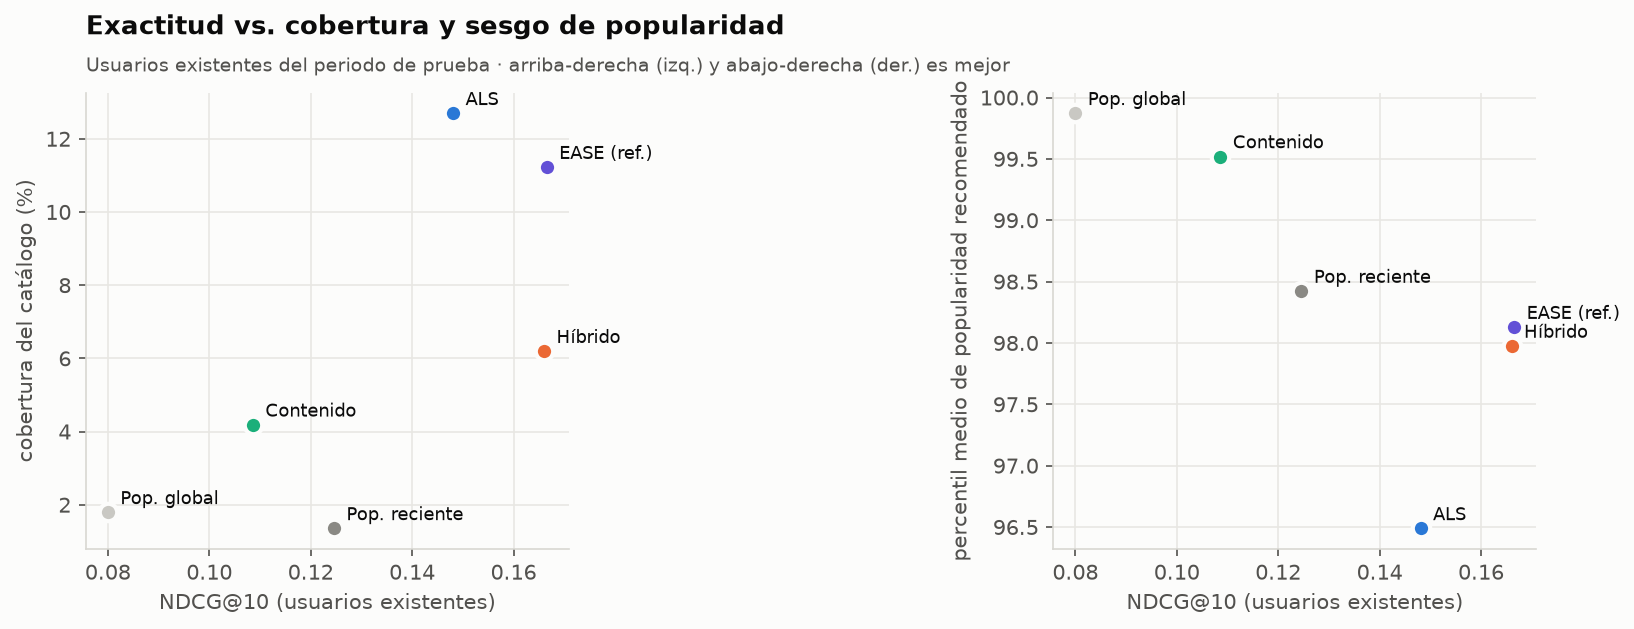

In [7]:
display(Image(str(C.FIGURAS / "03_exactitud_vs_popularidad.png")))

## Arranque en frío: ¿qué conviene preguntarle a un usuario nuevo?

In [8]:
nuevos = m[m.segmento == "nuevos (onboarding)"][["modelo", "ndcg@10", "recall@10", "hit_rate@10", "cobertura_pct", "percentil_pop_medio"]]
nuevos.sort_values("ndcg@10", ascending=False)

,modelo,ndcg@10,recall@10,hit_rate@10,cobertura_pct,percentil_pop_medio
23,Híbrido (ALS + contenido + recientes),0.4151,0.0867,0.9015,1.6021,99.6632
29,EASE (referencia),0.3846,0.0780,0.8979,12.3377,98.8165
13,ALS implícito,0.3666,0.0737,0.8860,10.1041,98.2841
8,Popularidad reciente,0.3640,0.0746,0.8482,0.0877,99.5966
18,Contenido (géneros + genome),0.3502,0.0695,0.8534,3.7715,99.7758
3,Popularidad global,0.2858,0.0530,0.7725,0.0877,99.9661
25,Contenido solo con géneros elegidos,0.2254,0.0393,0.7352,3.2569,99.3125


## Un ejemplo legible

In [9]:
res = json.load(open(C.REPORTES / "resultados.json", encoding="utf-8"))
ej = res["ejemplo"]
print("Le gustó (lo último antes de 2018):", "; ".join(ej["le_gusto_reciente"]))
print("\nRecomendado por el híbrido:", "; ".join(ej["recomendado_hibrido"]))
print("\nLe gustó después (prueba):", "; ".join(ej["acerto_en_prueba"]))

Le gustó (lo último antes de 2018): Inside Out (2015); Ghost in the Shell 2.0 (2008); Larry David: Curb Your Enthusiasm (1999); Ghost in the Shell: The New Movie (2015); Death Note Rewrite: Genshisuru Kami (2007); Arrival (2016); Rogue One: A Star Wars Story (2016); Logan (2017)

Recomendado por el híbrido: Up (2009); Fargo (1996); Matrix Reloaded, The (2003); Moon (2009); Seven (a.k.a. Se7en) (1995); Deadpool (2016); Skyfall (2012); Requiem for a Dream (2000); The Butterfly Effect (2004); Captain America: The First Avenger (2011)

Le gustó después (prueba): Akira (1988); Big Lebowski, The (1998); Last Emperor, The (1987); Dune (1984); Chicken Run (2000); Traffic (2000); Scarface (1983); Crimson Rivers, The (Rivières pourpres, Les) (2000); Score, The (2001); Training Day (2001)


## La API

`uvicorn api.main:app` levanta el servicio; aquí se llama con el cliente de pruebas de FastAPI (mismo código).

In [10]:
from fastapi.testclient import TestClient
from api.main import app
cli = TestClient(app)
print(cli.get("/salud").json())
u = cli.get("/usuarios_demo", params={"n": 5}).json()["usuarios"][2]
r = cli.get(f"/recomendar/{u}", params={"n": 5}).json()
print(f"usuario {u}: {r['positivos_en_historial']} positivos, segmento {r['segmento']}, peso ALS {r['peso_als']}")
pd.DataFrame(r["recomendaciones"])[["titulo", "anio", "puntaje", "porque_te_gusto"]]

{'estado': 'ok', 'version': '1.0.0', 'peliculas': 19937, 'usuarios_demo': 1500}
usuario 189: 133 positivos, segmento muchos (>100), peso ALS 0.816


,titulo,anio,puntaje,porque_te_gusto
0,Ocean's Eleven (2001),2001,15.7674,Snatch (2000)
1,"Truman Show, The (1998)",1998,15.5698,Metropolis (1927)
2,Trainspotting (1996),1996,14.0557,Fight Club (1999)
3,Much Ado About Nothing (1993),1993,14.0484,Shakespeare in Love (1998)
4,Star Wars: Episode IV - A New Hope (1977),1977,13.5964,Star Wars: Episode VI - Return of the Jedi (1983)


In [11]:
pd.DataFrame(cli.get("/similares/4993", params={"n": 5}).json()["similares"])[["titulo", "anio", "puntaje"]]

,titulo,anio,puntaje
0,"Lord of the Rings: The Two Towers, The (2002)",2002,10.8642
1,"Lord of the Rings: The Return of the King, The...",2003,10.5317
2,"Hobbit: An Unexpected Journey, The (2012)",2012,6.1543
3,"Hobbit: The Desolation of Smaug, The (2013)",2013,5.6509
4,The Hobbit: The Battle of the Five Armies (2014),2014,5.3272


In [12]:
pd.DataFrame(cli.post("/usuario_nuevo", json={"generos": ["Animación", "Comedia"]}, params={"n": 5}).json()["recomendaciones"])[["titulo", "anio", "generos"]]

,titulo,anio,generos
0,Wreck-It Ralph (2012),2012,"[Animation, Comedy]"
1,"Simpsons Movie, The (2007)",2007,"[Animation, Comedy]"
2,Toy Story (1995),1995,"[Adventure, Animation, Children, Comedy, Fantasy]"
3,Finding Nemo (2003),2003,"[Adventure, Animation, Children, Comedy]"
4,"South Park: Bigger, Longer and Uncut (1999)",1999,"[Animation, Comedy, Musical]"
